# Seasonal Variation Analysis

In [ ]:
import polars as pl
import matplotlib.pyplot as plt
import math

### 1. CONFIGURATION: Dataset selection 

In [ ]:
# Configuration of parameters

main_path = "/Users/jansigrist/Documents/SP/Customer_Segmentation_Lantern" # Adjust to your main path
clustering_method = 'kMed' # Options: 'kProt', 'kMed'
dataset = "SWW"    # Options: "SWW"
categorical_features = "technical" # "technical" or "sociodemographic"
building_type = 'house'  # Options: 'flat', 'house'

### 2. CONSUMPTION EXTRACTION: Extract seasonal consumption

In [ ]:
# Load results obtained in "Data Preprocessing" and "Clustering" steps

# Load clustering results from previous analysis
result_df=pl.read_csv(f'{main_path}/Results/{dataset}/DATA/Cluster/hourly_avg_clustering_{clustering_method}_{building_type}_{categorical_features}.csv')

# Load dataset_summary_stats: Ensure seasonal stats are available
dataset_summary_stats_df = pl.read_csv(f"{main_path}/DATA/{dataset}/dataset_summary_stats.csv")

result_df = result_df.with_columns(
    pl.col("resident_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

dataset_summary_stats_df = dataset_summary_stats_df.with_columns(
    pl.col("file_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

result_df = result_df.join(
    dataset_summary_stats_df.select([
        "resident_id",
        "bruttolastgang_kwh_sum",
        "avg_daily_spring",
        "avg_daily_summer",
        "avg_daily_autumn",
        "avg_daily_winter"
    ]),
    on="resident_id",
    how="left"
)
result_df = result_df.select([
    "resident_id",
    "cluster",
    "bruttolastgang_kwh_sum",
    "avg_daily_spring",
    "avg_daily_summer",
    "avg_daily_autumn",
    "avg_daily_winter"
])

cluster_summary = result_df.group_by("cluster").agg([
    pl.count("resident_id").alias("num_households"),
    pl.mean("bruttolastgang_kwh_sum").alias("avg_yearly_consumption [kWh]"),
    pl.mean("avg_daily_spring").alias("Spring [kWh]").round(1),
    pl.mean("avg_daily_summer").alias("Summer [kWh]").round(1),
    pl.mean("avg_daily_autumn").alias("Autumn [kWh]").round(1),
    pl.mean("avg_daily_winter").alias("Winter [kWh]").round(1),
]).sort("cluster")

# Compute overall averages
overall_yearly_avg = result_df["bruttolastgang_kwh_sum"].mean()
overall_day_avg_spring = result_df['avg_daily_spring'].mean()
overall_day_avg_summer = result_df['avg_daily_summer'].mean()
overall_day_avg_autumn = result_df['avg_daily_autumn'].mean()
overall_day_avg_winter = result_df['avg_daily_winter'].mean()

cluster_summary = cluster_summary.with_columns([
    pl.col("cluster").cast(pl.Utf8)
])
summary_row = pl.DataFrame({
    "cluster": ["Average"],
    "num_households": [result_df["resident_id"].n_unique()],
    "avg_yearly_consumption [kWh]": [overall_yearly_avg],
    "Spring [kWh]": [overall_day_avg_spring],
    "Summer [kWh]": [overall_day_avg_summer],
    "Autumn [kWh]": [overall_day_avg_autumn],
    "Winter [kWh]": [overall_day_avg_winter]
})

# Ensure consistent data types before concatenation
summary_row = summary_row.with_columns([
    pl.col("cluster").cast(cluster_summary["cluster"].dtype),
    pl.col("num_households").cast(cluster_summary["num_households"].dtype)
])

final_summary = pl.concat([cluster_summary])

print(final_summary)

shape: (6, 7)
┌─────────┬───────────────┬───────────────┬────────┬───────────────┬───────────────┬───────────────┐
│ cluster ┆ num_household ┆ avg_yearly_co ┆ Spring ┆ Summer [kWh]  ┆ Autumn [kWh]  ┆ Winter [kWh]  │
│ ---     ┆ s             ┆ nsumption     ┆ [kWh]  ┆ ---           ┆ ---           ┆ ---           │
│ str     ┆ ---           ┆ [kWh]         ┆ ---    ┆ f64           ┆ f64           ┆ f64           │
│         ┆ u32           ┆ ---           ┆ f64    ┆               ┆               ┆               │
│         ┆               ┆ f64           ┆        ┆               ┆               ┆               │
╞═════════╪═══════════════╪═══════════════╪════════╪═══════════════╪═══════════════╪═══════════════╡
│ 1       ┆ 73            ┆ 6254.434192   ┆ 15.0   ┆ 7.6           ┆ 17.5          ┆ 28.4          │
│ 2       ┆ 125           ┆ 3327.106648   ┆ 9.0    ┆ 7.8           ┆ 9.4           ┆ 10.2          │
│ 3       ┆ 70            ┆ 7682.222329   ┆ 19.9   ┆ 11.7          ┆ 20.7    

### 3. RESULT VISUALIZATION: Change in daily consumption across seasons with different legend titles

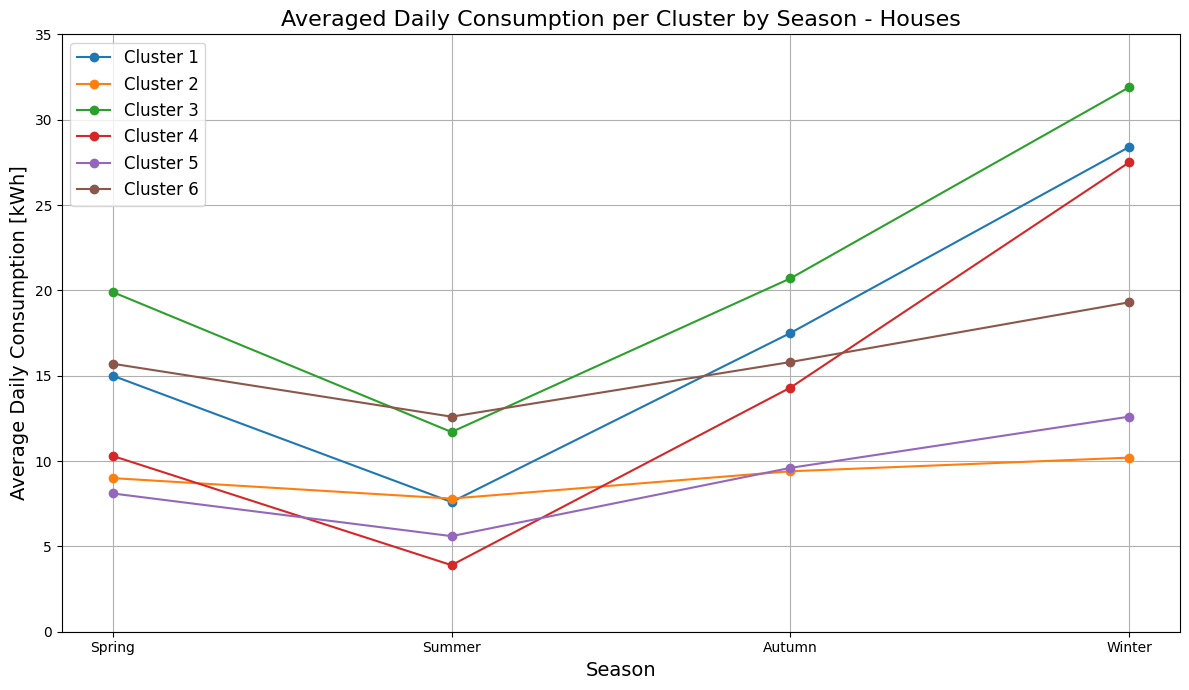

In [ ]:
# Plotting the seasonal consumption patterns per cluster

colors= ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728','#9467bd', '#8c564b']
linestyles = ['-', '-', '-', '-', '-', '-']

seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
clusters = final_summary["cluster"].to_list()

plt.figure(figsize=(12, 7))
i = 0

# Plot each cluster's seasonal consumption
for cluster in clusters:
    
    row = final_summary.filter(pl.col("cluster") == cluster).select([
        "Spring [kWh]", "Summer [kWh]", "Autumn [kWh]", "Winter [kWh]"
    ])
    consumption = row[0, :].to_numpy().flatten().tolist()
    plt.plot(seasons, consumption, marker='o', linestyle = linestyles[i],  label=f"Cluster {cluster}" , color = colors[i])
    i = i+1

plt.xlabel('Season', fontsize=14)
plt.ylabel('Average Daily Consumption [kWh]', fontsize=14)
plt.title(f'Averaged Daily Consumption per Cluster by Season - {building_type.capitalize()}s', fontsize=16)
max_value = final_summary.select(
    pl.max(["Winter [kWh]"])
).max()[0].to_numpy().flatten()[0]

plt.ylim(0, math.ceil((max_value) / 5) * 5)
plt.grid(True)
plt.legend(fontsize='large')
plt.tight_layout()
plt.savefig(
    f'{main_path}/Results/{dataset}/Plots/Cluster/Seasonal_Evolution_{clustering_method}_{building_type}_{categorical_features}.png',
    bbox_inches='tight'
    )
plt.show()


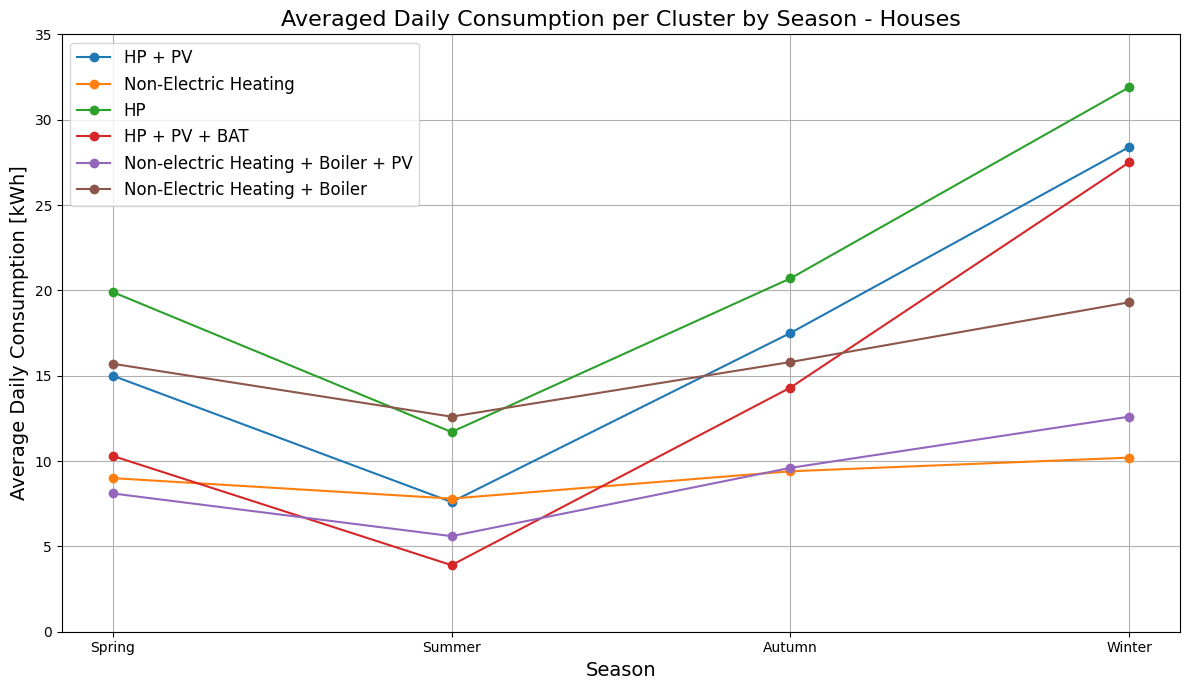

In [ ]:
# Plotting the seasonal consumption patterns per cluster with specific cluster names (useful for presentation)

colors= ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728','#9467bd', '#8c564b']
linestyles = ['-', '-', '-', '-', '-', '-']

# Cluster names are specificly defined for the technical distribution
# Change the names accordingly for different clustering results

if building_type == 'flat':
    cluster_names = ['Washing Machine', 'Basic Flat', 'Boiler', 'Boiler + Washing Machine']
elif building_type == 'house':
    cluster_names = ['HP + PV', 'Non-Electric Heating', 'HP', 'HP + PV + BAT', 'Non-electric Heating + Boiler + PV', 'Non-Electric Heating + Boiler']

seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
clusters = final_summary["cluster"].to_list()

plt.figure(figsize=(12, 7))
i = 0

for cluster in clusters:
    
    row = final_summary.filter(pl.col("cluster") == cluster).select([
        "Spring [kWh]", "Summer [kWh]", "Autumn [kWh]", "Winter [kWh]"
    ])
    consumption = row[0, :].to_numpy().flatten().tolist()
    plt.plot(seasons, consumption, marker='o', linestyle = linestyles[i],  label=cluster_names[i] , color = colors[i])
    i = i+1

plt.xlabel('Season', fontsize=14)
plt.ylabel('Average Daily Consumption [kWh]', fontsize=14)
plt.title(f'Averaged Daily Consumption per Cluster by Season - {building_type.capitalize()}s', fontsize=16)
max_value = final_summary.select(
    pl.max(["Winter [kWh]"])
).max()[0].to_numpy().flatten()[0]

plt.ylim(0, math.ceil((max_value) / 5) * 5)
plt.grid(True)
plt.legend(fontsize='large')
plt.tight_layout()
plt.savefig(
    f'{main_path}/Results/{dataset}/Plots/Cluster/Seasonal_Evolution_{clustering_method}_{building_type}_{categorical_features}.png',
    bbox_inches='tight'
    )
plt.show()
